# Surveillance Épidémiologique AMR (2019–2025) : Construction, Audit et Validation des Populations Dédupliquées (WHO GLASS & Épisodes 14j / 30j / 365j)

**Objectif du notebook :**
Construire de manière reproductible, auditable et non destructive quatre populations analytiques d'isolats bactériens à partir de `data.parquet` (2019–2025) :
- `df_glass` : déduplication annuelle selon le manuel **WHO GLASS** (avec gestion explicite de l'exception clinique **Sang / LCR le même jour**).
- `df_14j` : déduplication par épisode infectieux de **14 jours** (`AMR.first_isolate(method="episode-based", episode_days=14)`).
- `df_30j` : déduplication par épisode infectieux de **30 jours** (`AMR.first_isolate(method="episode-based", episode_days=30)`).
- `df_365j` : déduplication par épisode infectieux de **365 jours** (`AMR.first_isolate(method="episode-based", episode_days=365)`).

> **Important :** Conformément au protocole biostatistique, cette étape se concentre exclusivement sur la **construction, l'audit et la validation des quatre dénominateurs analytiques** (sans recalculer les taux de résistance `%R`, qui feront l'objet de l'étape comparative suivante).


## 1. Configuration centralisée, vérification du package `AMR` et inspection des colonnes

Nous importons le module réutilisable [`amr_deduplication.py`](./amr_deduplication.py) qui centralise :
- Le dictionnaire de correspondance des colonnes (`DEFAULT_COLUMN_MAPPING`) et la configuration épidémiologique (`DeduplicationConfig`).
- L'interfaçage avec le package Python `AMR` (`AMR.first_isolate`).
- Les fonctions `dedup_glass`, `dedup_episode`, `validate_deduplication`, `summarize_deduplication` et `compare_methods`.


In [18]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

import AMR
import amr_deduplication as ad
from amr_deduplication import (
    DeduplicationConfig,
    DEFAULT_COLUMN_MAPPING,
    WHO_GLASS_STRICT_PAIRS,
    inspect_and_map_columns,
    prepare_amr_dataframe,
    dedup_glass,
    dedup_episode,
    run_all_deduplications,
    export_deduplication_outputs,
    summarize_deduplication,
    compare_methods,
    validate_deduplication,
    validate_synthetic_cases,
    build_synthetic_test_data,
    plot_f1_annual_retained,
    plot_f2_excluded_percentage,
    plot_f3_species_heatmap,
    METHODOLOGICAL_NOTE_GLASS_VS_365J,
)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 140)
print(f"Package Python AMR chargé avec succès : HAS_AMR_PACKAGE = {ad.HAS_AMR_PACKAGE}")


ImportError: cannot import name 'export_deduplication_outputs' from 'amr_deduplication' (/Users/slimane/biologie/AMR/codeAnalyse/amr_deduplication.py)

In [ ]:
# Chemin de la base en entrée et dossier d'enregistrement des fichiers de sortie
INPUT_DATA_PATH = "data.parquet"
OUTPUT_DIR = "outputs_deduplication"  # Dossier où seront enregistrés df_glass, df_14j, df_30j, df_365j
EXPORT_PARQUET = True
EXPORT_CSV = True

# Initialisation de la configuration centralisée
config = DeduplicationConfig(
    year_min=2019,
    year_max=2025,
    episode_windows=(14, 30, 365),
    use_infection_origin_if_reliable=True,
    origin_min_completeness=0.80,
    apply_glass_blood_csf_exception=True,
    apply_episode_blood_csf_exception=False,
    eligibility_scope="all_eligible",  # Conserve tous les isolats harmonisés éligibles et flagge aussi le périmètre strict GLASS
    use_amr_package=True,
)

# Chargement de la base source et vérification dynamique des colonnes
df_raw = pd.read_parquet(INPUT_DATA_PATH)
col_report = inspect_and_map_columns(df_raw, config=config, verbose=True)


VÉRIFICATION DES COLONNES DU DATAFRAME ET DICTIONNAIRE DE CORRESPONDANCE
Dimensions de la table source : 3,485,983 lignes × 40 colonnes
  Concept_Logique            Colonne_DataFrame  Presente  Completude_%  Valeurs_Distinctes
       isolate_id                      ROW_UID      True        100.00              179623
       patient_id                   PATIENT_ID      True        100.00              332098
  collection_date     SPECIMEN_COLLECTION_DATE      True         94.67                2565
    analysis_date                ANALYSIS_DATE      True          0.47                 556
             year                         YEAR      True        100.00                   7
    organism_code                ORGANISM_CODE      True         78.25                  22
    organism_name                ORGANISM_NAME      True         78.25                  22
    specimen_type                SPECIMEN_TYPE      True         90.69                 132
  specimen_source              SPECIMEN_SOURC

## 2. Préparation non destructive de `df_amr` (1 ligne par isolat unique + conservation intégrale des résultats AST)

La table `data.parquet` stocke les résultats d'antibiogrammes au format long (`3 485 983` lignes pour `179 623` isolats uniques identifiés par `ROW_UID`).
La fonction `prepare_amr_dataframe()` consolide une ligne par isolat unique dans `df_amr` :
- **Aucune observation originale n'est supprimée** (`179 623` isolats conservés).
- **Tous les résultats d'antibiogramme (AST)** sont conservés dans les colonnes `ABX_<CODE>` (77 antibiotiques), accompagnés de `AST_TESTED_COUNT` et `AST_PROFILE`.
- Les isolats non éligibles sont identifiés par `IS_ELIGIBLE = False` et documentés dans `ELIGIBILITY_REASON`.
- La distinction entre l'**éligibilité générale** (`IS_ELIGIBLE`) et le **périmètre strict des couples Pathogène × Prélèvement du rapport WHO GLASS** (`IS_GLASS_WHO_SCOPE`) est explicitement conservée.


In [ ]:
df_amr = prepare_amr_dataframe(df_raw, config=config, verbose=True)

print("\nRépartition des motifs d'éligibilité sur l'ensemble des 179 623 isolats de df_amr :")
display(
    df_amr["ELIGIBILITY_REASON"]
    .value_counts()
    .rename_axis("Motif_Eligibilite")
    .reset_index(name="Nombre_Isolats")
)


[prepare_amr_dataframe] Isolats uniques (ROW_UID) : 179,623
  - Isolats éligibles (analyse générale 2019–2025) : 87,108 (48.5%)
  - Isolats dans le périmètre strict WHO GLASS     : 74,494 (41.5%)
  - Complétude de l'origine CAI/HAI                : 22.6% (stratification active : False)

Répartition des motifs d'éligibilité sur l'ensemble des 179 623 isolats de df_amr :


,Motif_Eligibilite,Nombre_Isolats
0,ELIGIBLE,87108
1,INELIGIBLE_EXCLUDED_OR_UNHARMONIZED_SPECIMEN,49464
2,INELIGIBLE_MISSING_ORGANISM,41249
3,INELIGIBLE_DATE_OR_OUT_OF_RANGE_2019_2025,1802


## 3. Application des quatre règles de déduplication (`df_glass`, `df_14j`, `df_30j`, `df_365j`)

### Règles de départage des prélèvements simultanés et exception Sang / LCR :
1. **Exception WHO GLASS Sang / LCR (`apply_glass_blood_csf_exception=True`) :**
   Si un même patient présente la même espèce bactérienne dans le sang (`Blood`) et dans le liquide céphalorachidien (`Cerebrospinal fluid`) le **même jour calendaire**, le prélèvement `Cerebrospinal fluid` est prioritaire et l'isolat `Blood` du même jour est exclu avec le motif `EXCLUDED_GLASS_BLOOD_SAME_DAY_AS_CSF`.
2. **Analyses secondaires par épisodes (14j, 30j, 365j) :**
   Les épisodes sont définis par strate `(PATIENT_ID, ORGANISM_CODE, SPECIMEN_TYPE[, INFECTION_ORIGIN])` via `AMR.first_isolate(method="episode-based", episode_days=days)`. Chaque fenêtre est ancrée sur la **date de début de l'épisode** ($E_m$), sans réinitialisation au changement d'année civile (chronologie continue 2019–2025) et sans réouverture d'épisode en cas de modification de l'antibiogramme.
3. **Départage déterministe des prélèvements simultanés :**
   En cas d'isolats multiples dans la même strate le même jour, l'ordre de priorité est :
   `(1) Priorité clinique du prélèvement > (2) Horodatage exact > (3) Nombre d'antibiotiques testés (-AST_TESTED_COUNT) > (4) Ordre lexicographique de ROW_UID`.
   Cette règle garantit une **invariance totale** à l'ordre initial des lignes.


In [ ]:
# Exécution des 4 méthodes et création des 4 DataFrames sous-ensembles
df_amr, df_glass, df_14j, df_30j, df_365j = run_all_deduplications(df_amr, config=config)

print("Dimensions des DataFrames générés :")
print(f"  - df_amr   (base complète conservée) : {df_amr.shape[0]:>7,} isolats × {df_amr.shape[1]} colonnes")
print(f"  - df_glass (WHO GLASS annuel)        : {df_glass.shape[0]:>7,} isolats retenus")
print(f"  - df_14j   (Épisode 14 jours)        : {df_14j.shape[0]:>7,} isolats retenus")
print(f"  - df_30j   (Épisode 30 jours)        : {df_30j.shape[0]:>7,} isolats retenus")
print(f"  - df_365j  (Épisode 365 jours)       : {df_365j.shape[0]:>7,} isolats retenus")

print("\nConcordance exacte avec AMR.first_isolate :")
for w in (14, 30, 365):
    print(f"  - Fenêtre {w:>3}j : concordance AMR.first_isolate = {df_amr.attrs.get(f'amr_package_concordance_{w}j')}")


Dimensions des DataFrames générés :
  - df_amr   (base complète conservée) : 179,623 isolats × 135 colonnes
  - df_glass (WHO GLASS annuel)        :  86,057 isolats retenus
  - df_14j   (Épisode 14 jours)        :  86,297 isolats retenus
  - df_30j   (Épisode 30 jours)        :  86,250 isolats retenus
  - df_365j  (Épisode 365 jours)       :  86,060 isolats retenus

Concordance exacte avec AMR.first_isolate :
  - Fenêtre  14j : concordance AMR.first_isolate = True
  - Fenêtre  30j : concordance AMR.first_isolate = True
  - Fenêtre 365j : concordance AMR.first_isolate = True


In [ ]:
# Audit des cas réels de l'exception WHO GLASS Sang / LCR le même jour dans data.parquet
csf_blood_audit = df_amr[
    df_amr["glass_decision_reason"].isin([
        "EXCLUDED_GLASS_BLOOD_SAME_DAY_AS_CSF",
        "SELECTED_FIRST_GLASS_CSF_PRIORITY_OVER_BLOOD"
    ])
][[
    "ROW_UID", "PATIENT_ID", "ISOLATE_DATE", "ORGANISM_NAME", "SPECIMEN_TYPE",
    "first_glass", "glass_decision_reason", "first_14j", "first_30j", "first_365j"
]].sort_values(["PATIENT_ID", "ISOLATE_DATE", "SPECIMEN_TYPE"])

print(f"Cas réels d'isolats simultanés Sang + LCR le même jour détectés et traités ({len(csf_blood_audit)} isolats chez {csf_blood_audit['PATIENT_ID'].nunique()} patients) :")
display(csf_blood_audit)


Cas réels d'isolats simultanés Sang + LCR le même jour détectés et traités (6 isolats chez 3 patients) :


,ROW_UID,PATIENT_ID,ISOLATE_DATE,ORGANISM_NAME,SPECIMEN_TYPE,first_glass,glass_decision_reason,first_14j,first_30j,first_365j
37633,e4399d6a87202c18:00005121,PAT_068621,2019-12-20,Streptococcus pneumoniae,Blood,False,EXCLUDED_GLASS_BLOOD_SAME_DAY_AS_CSF,True,True,True
37634,e4399d6a87202c18:00005122,PAT_068621,2019-12-20,Streptococcus pneumoniae,Cerebrospinal fluid,True,SELECTED_FIRST_GLASS_CSF_PRIORITY_OVER_BLOOD,True,True,True
113918,7a91c0018c370100:00003758,PAT_212181,2021-12-01,Staphylococcus aureus,Blood,False,EXCLUDED_GLASS_BLOOD_SAME_DAY_AS_CSF,True,True,True
113917,7a91c0018c370100:00003757,PAT_212181,2021-12-01,Staphylococcus aureus,Cerebrospinal fluid,True,SELECTED_FIRST_GLASS_CSF_PRIORITY_OVER_BLOOD,True,True,True
146343,408a62e3582fa823:00002154,PAT_274250,2024-09-02,Klebsiella pneumoniae,Blood,False,EXCLUDED_GLASS_BLOOD_SAME_DAY_AS_CSF,True,True,True
146342,408a62e3582fa823:00002153,PAT_274250,2024-09-02,Klebsiella pneumoniae,Cerebrospinal fluid,True,SELECTED_FIRST_GLASS_CSF_PRIORITY_OVER_BLOOD,True,True,True


## 4. Indicateurs épidémiologiques et Tableaux D1, D2 et D3


In [ ]:
summaries = summarize_deduplication(df_amr, config=config)
comparison_summary = compare_methods(df_amr, config=config)

print("=== SYNTHÈSE GLOBALE COMPARATIVE DES 4 MÉTHODES (2019–2025) ===")
display(comparison_summary)


=== SYNTHÈSE GLOBALE COMPARATIVE DES 4 MÉTHODES (2019–2025) ===


,Methode,Isolats_Eligibles,Isolats_Retenus,Isolats_Exclus,Pct_Retenus,Pct_Exclus,Patients_Distincts_Retenus,Concordance_avec_GLASS_%
0,WHO GLASS (Annuel),87108,86057,1051,98.79,1.21,83040,100.00
1,Épisode 14 jours,87108,86297,811,99.07,0.93,83040,99.72
2,Épisode 30 jours,87108,86250,858,99.02,0.98,83040,99.78
3,Épisode 365 jours,87108,86060,1048,98.80,1.20,83040,100.00


### Tableau D1 — Tableau annuel de déduplication WHO GLASS (effectifs avant/après et pourcentage exclu)


In [ ]:
d1_table = summaries["D1_annual_glass"]
display(d1_table)


,Annee,Isolats_Eligibles,Isolats_Retenus,Isolats_Exclus,Pct_Retenus,Pct_Exclus,Patients_Distincts_Retenus
0,2019,10732,10565,167,98.44,1.56,10145
1,2020,9013,8963,50,99.45,0.55,8768
2,2021,13087,12872,215,98.36,1.64,12427
3,2022,12225,12079,146,98.81,1.19,11499
4,2023,15695,15492,203,98.71,1.29,15016
5,2024,14327,14154,173,98.79,1.21,13642
6,2025,12029,11932,97,99.19,0.81,11544
7,Total 2019-2025,87108,86057,1051,98.79,1.21,83040


### Tableau D2 — Tableau comparatif des quatre méthodes par année (2019–2025)


In [ ]:
d2_table = summaries["D2_methods_comparison"]
display(d2_table)


,Annee,Isolats_Eligibles_Avant_Dedup,Patients_Distincts,Retenus_GLASS,Pct_Exclus_GLASS,Retenus_14j,Pct_Exclus_14j,Retenus_30j,Pct_Exclus_30j,Retenus_365j,Pct_Exclus_365j,Ecart_GLASS_vs_365j
0,2019,10732,10145,10565,1.56,10591,1.31,10586,1.36,10566,1.55,-1
1,2020,9013,8768,8963,0.55,8972,0.45,8970,0.48,8963,0.55,0
2,2021,13087,12427,12872,1.64,12940,1.12,12929,1.21,12873,1.64,-1
3,2022,12225,11499,12079,1.19,12110,0.94,12106,0.97,12079,1.19,0
4,2023,15695,15016,15492,1.29,15572,0.78,15552,0.91,15492,1.29,0
5,2024,14327,13642,14154,1.21,14168,1.11,14167,1.12,14155,1.20,-1
6,2025,12029,11544,11932,0.81,11944,0.71,11940,0.74,11932,0.81,0
7,Total 2019-2025,87108,83040,86057,1.21,86297,0.93,86250,0.98,86060,1.20,-3


### Tableau D3 — Tableau par espèce bactérienne et par type de prélèvement selon les quatre méthodes


In [ ]:
print("1. Synthèse par espèce bactérienne (22 espèces harmonisées) :")
display(summaries["by_species"])

print("\n2. Synthèse par type de prélèvement :")
display(summaries["by_specimen"])

print("\n3. Tableau D3 complet (Espèce × Prélèvement, Top 30 strates par effectif) :")
d3_table = summaries["D3_species_specimen"]
display(d3_table.head(30))


1. Synthèse par espèce bactérienne (22 espèces harmonisées) :


,Code_Espece,Espece_Bacterienne,Eligibles,Patients_Distincts,Retenus_GLASS,Retenus_14j,Retenus_30j,Retenus_365j,Pct_Exclus_GLASS,Pct_Exclus_14j,Pct_Exclus_30j,Pct_Exclus_365j
0,B_ESCHR_COLI,Escherichia coli,38697,38368,38397,38453,38447,38397,0.78,0.63,0.65,0.78
1,B_KLBSL_PNMN,Klebsiella pneumoniae,17381,17188,17260,17282,17280,17261,0.70,0.57,0.58,0.69
2,B_PSDMN_AERG,Pseudomonas aeruginosa,7769,7433,7476,7545,7523,7476,3.77,2.88,3.17,3.77
3,B_STPHY_AURS,Staphylococcus aureus,5778,5699,5722,5728,5727,5723,0.97,0.87,0.88,0.95
4,B_ACNTB_BMNN,Acinetobacter baumannii,4432,4282,4342,4352,4348,4342,2.03,1.81,1.90,2.03
5,B_ENTRBC_CLOC,Enterobacter cloacae,2998,2975,2984,2986,2986,2984,0.47,0.40,0.40,0.47
6,B_ENTRC_FCLS,Enterococcus faecalis,2968,2919,2929,2942,2937,2929,1.31,0.88,1.04,1.31
7,B_HMPHL_INFL,Haemophilus influenzae,1899,1842,1846,1853,1853,1846,2.79,2.42,2.42,2.79
8,B_STRPT_AGLC,Streptococcus agalactiae,1846,1773,1786,1835,1829,1786,3.25,0.60,0.92,3.25
9,B_ENTRC_FACM,Enterococcus faecium,1066,1054,1060,1060,1060,1060,0.56,0.56,0.56,0.56



2. Synthèse par type de prélèvement :


,Type_Prelevement,Eligibles,Patients_Distincts,Retenus_GLASS,Retenus_14j,Retenus_30j,Retenus_365j,Pct_Exclus_GLASS,Pct_Exclus_14j,Pct_Exclus_30j,Pct_Exclus_365j
0,Urine,55857,54766,55406,55504,55490,55406,0.81,0.63,0.66,0.81
1,Lower respiratory tract specimen,16769,15454,16342,16424,16400,16342,2.55,2.06,2.20,2.55
2,Blood,12308,12052,12199,12209,12208,12202,0.89,0.80,0.81,0.86
3,Genital specimen,1471,1400,1414,1461,1455,1414,3.87,0.68,1.09,3.87
4,Cerebrospinal fluid,478,472,473,474,474,473,1.05,0.84,0.84,1.05
5,Upper respiratory tract specimen,117,113,116,117,116,116,0.85,0.00,0.85,0.85
6,Stool,108,107,107,108,107,107,0.93,0.00,0.93,0.93



3. Tableau D3 complet (Espèce × Prélèvement, Top 30 strates par effectif) :


,Code_Espece,Espece_Bacterienne,Type_Prelevement,Strict_WHO_GLASS,Eligibles,Patients_Distincts,Retenus_GLASS,Retenus_14j,Retenus_30j,Retenus_365j,Pct_Exclus_GLASS,Pct_Exclus_14j,Pct_Exclus_30j,Pct_Exclus_365j
0,B_ESCHR_COLI,Escherichia coli,Urine,True,36586,36292,36292,36346,36340,36292,0.80,0.66,0.67,0.80
1,B_KLBSL_PNMN,Klebsiella pneumoniae,Urine,True,10689,10622,10622,10639,10638,10622,0.63,0.47,0.48,0.63
2,B_PSDMN_AERG,Pseudomonas aeruginosa,Lower respiratory tract specimen,True,5244,4994,4995,5053,5034,4995,4.75,3.64,4.00,4.75
3,B_KLBSL_PNMN,Klebsiella pneumoniae,Lower respiratory tract specimen,True,3371,3335,3335,3338,3337,3335,1.07,0.98,1.01,1.07
4,B_KLBSL_PNMN,Klebsiella pneumoniae,Blood,True,3151,3134,3133,3135,3135,3134,0.57,0.51,0.51,0.54
5,B_STPHY_AURS,Staphylococcus aureus,Blood,True,2633,2599,2598,2603,2602,2599,1.33,1.14,1.18,1.29
6,B_ENTRC_FCLS,Enterococcus faecalis,Urine,False,2447,2412,2412,2425,2420,2412,1.43,0.90,1.10,1.43
7,B_ACNTB_BMNN,Acinetobacter baumannii,Lower respiratory tract specimen,True,2291,2229,2229,2238,2234,2229,2.71,2.31,2.49,2.71
8,B_STPHY_AURS,Staphylococcus aureus,Lower respiratory tract specimen,True,2158,2141,2141,2141,2141,2141,0.79,0.79,0.79,0.79
9,B_HMPHL_INFL,Haemophilus influenzae,Lower respiratory tract specimen,True,1831,1779,1779,1786,1786,1779,2.84,2.46,2.46,2.84


In [ ]:
# Comparaison complémentaire : Périmètre général éligible vs Périmètre strict des couples WHO GLASS
elig_all = df_amr[df_amr["IS_ELIGIBLE"]]
elig_strict = df_amr[df_amr["IS_GLASS_WHO_SCOPE"]]

scope_comp = pd.DataFrame([
    {
        "Perimetre": "Tous isolats éligibles harmonisés (22 espèces)",
        "Isolats_Eligibles": len(elig_all),
        "Patients_Distincts": elig_all["PATIENT_ID"].nunique(),
        "Retenus_GLASS": int(elig_all["first_glass"].sum()),
        "Retenus_14j": int(elig_all["first_14j"].sum()),
        "Retenus_30j": int(elig_all["first_30j"].sum()),
        "Retenus_365j": int(elig_all["first_365j"].sum()),
    },
    {
        "Perimetre": "Périmètre strict des couples Pathogène × Prélèvement WHO GLASS",
        "Isolats_Eligibles": len(elig_strict),
        "Patients_Distincts": elig_strict["PATIENT_ID"].nunique(),
        "Retenus_GLASS": int(elig_strict["first_glass"].sum()),
        "Retenus_14j": int(elig_strict["first_14j"].sum()),
        "Retenus_30j": int(elig_strict["first_30j"].sum()),
        "Retenus_365j": int(elig_strict["first_365j"].sum()),
    },
])
print("=== COMPARAISON PÉRIMÈTRE GÉNÉRAL ÉLIGIBLE vs PÉRIMÈTRE STRICT WHO GLASS ===")
display(scope_comp)


=== COMPARAISON PÉRIMÈTRE GÉNÉRAL ÉLIGIBLE vs PÉRIMÈTRE STRICT WHO GLASS ===


,Perimetre,Isolats_Eligibles,Patients_Distincts,Retenus_GLASS,Retenus_14j,Retenus_30j,Retenus_365j
0,Tous isolats éligibles harmonisés (22 espèces),87108,83040,86057,86297,86250,86060
1,Périmètre strict des couples Pathogène × Prélè...,74494,71775,73608,73773,73740,73611


## 5. Figures F1, F2 et F3


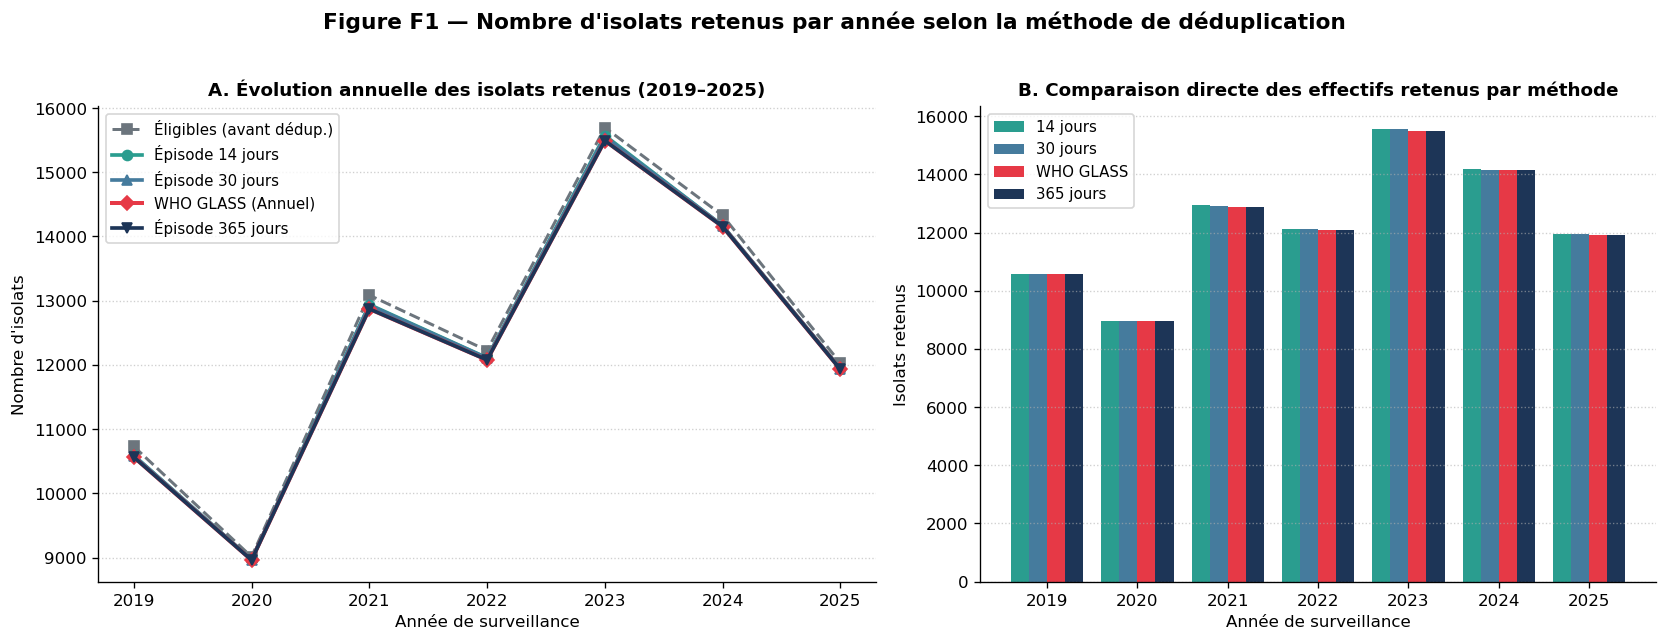

In [ ]:
# Figure F1 — Nombre d'isolats retenus par année selon les quatre méthodes
Path("figures_deduplication").mkdir(exist_ok=True)
fig_f1 = plot_f1_annual_retained(summaries, save_path="figures_deduplication/F1_isolats_retenus_annuel.png")
plt.show()


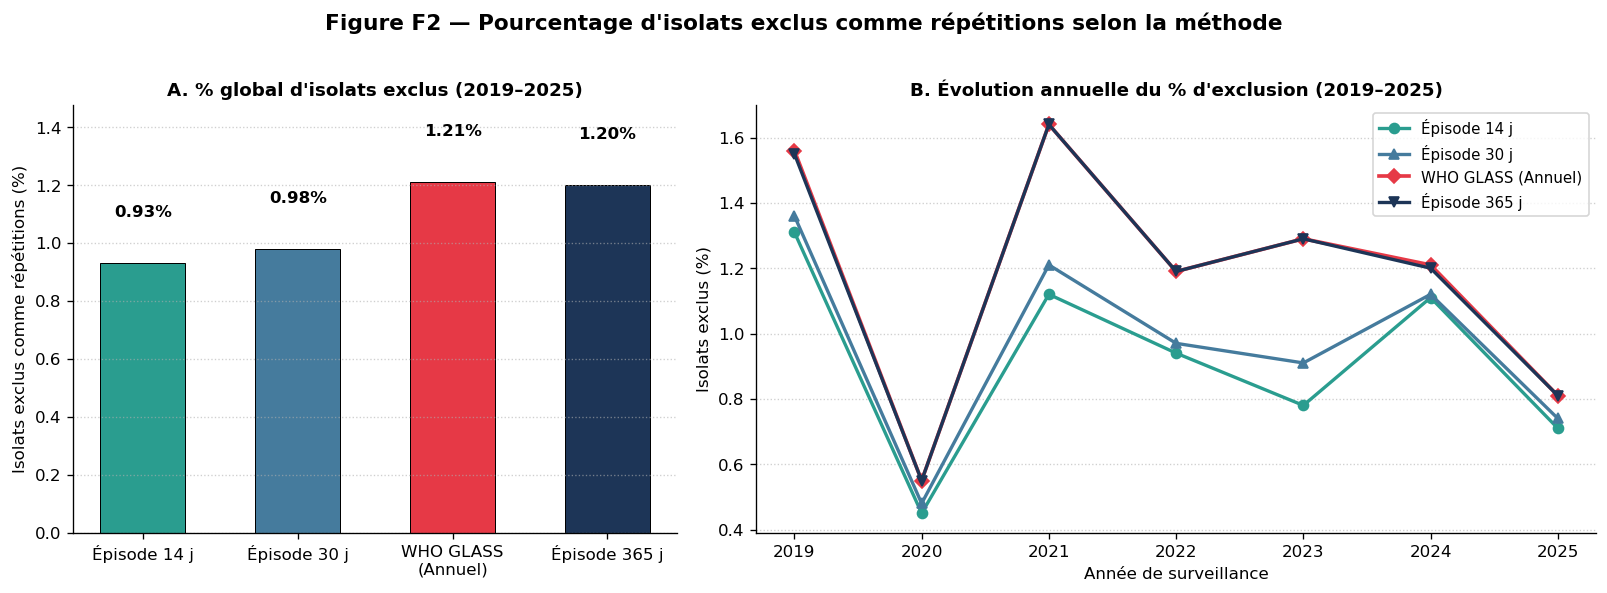

In [ ]:
# Figure F2 — Pourcentage d'isolats exclus selon la méthode
fig_f2 = plot_f2_excluded_percentage(summaries, save_path="figures_deduplication/F2_pourcentage_exclus_methodes.png")
plt.show()


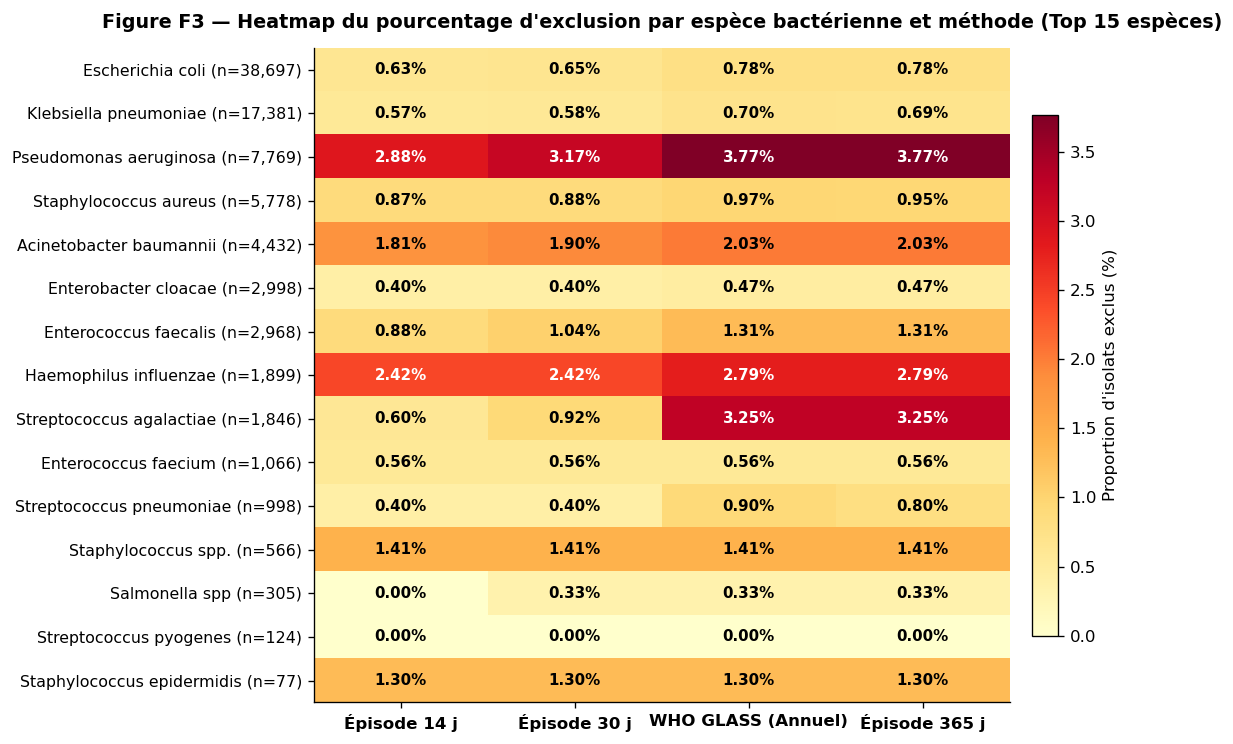

In [ ]:
# Figure F3 — Heatmap de la proportion d'exclusion par espèce bactérienne et méthode
fig_f3 = plot_f3_species_heatmap(summaries, top_n=15, save_path="figures_deduplication/F3_heatmap_exclusion_especes.png")
plt.show()


## 6. Validation automatique et Tests sur données synthétiques (Cas limites J0, J13, J15, J29, J30, J365, frontière d'année, AST, Sang/LCR)


In [ ]:
# 6.1 Validation sur le jeu de données synthétique couvrant tous les cas particuliers
syn_amr, syn_cases_report = validate_synthetic_cases(config=config)

print("=== RAPPORT DE VALIDATION DES CAS PARTICULIERS SUR DONNÉES SYNTHÉTIQUES ===")
display(syn_cases_report)

print("\nDétail ligne à ligne des décisions sur le jeu synthétique :")
display(
    syn_amr[[
        "ROW_UID", "PATIENT_ID", "ISOLATE_DATE", "ORGANISM_CODE", "SPECIMEN_TYPE",
        "ABX_CTX", "IS_ELIGIBLE", "first_glass", "first_14j", "first_30j", "first_365j",
        "days_since_start_14j", "days_since_start_30j", "days_since_start_365j",
        "glass_decision_reason"
    ]]
)


=== RAPPORT DE VALIDATION DES CAS PARTICULIERS SUR DONNÉES SYNTHÉTIQUES ===


,Cas_Synthetique,Attendu,Observe,Statut
0,C1a. Séquence J0..J365 (GLASS annuel),['SYN01_J000'],['SYN01_J000'],PASS
1,C1b. Séquence J0..J365 (Épisode 14j : ancrage ...,"['SYN01_J000', 'SYN01_J015', 'SYN01_J029', 'SY...","['SYN01_J000', 'SYN01_J015', 'SYN01_J029', 'SY...",PASS
2,C1c. Séquence J0..J365 (Épisode 30j : ancrage ...,"['SYN01_J000', 'SYN01_J030', 'SYN01_J365']","['SYN01_J000', 'SYN01_J030', 'SYN01_J365']",PASS
3,C1d. Séquence J0..J365 (Épisode 365j : réouver...,"['SYN01_J000', 'SYN01_J365']","['SYN01_J000', 'SYN01_J365']",PASS
4,C2. Changement d'année (2021-12-25 -> 2022-01-...,"GLASS=True, 14j=False, 30j=False, 365j=False","GLASS=True, 14j=False, 30j=False, 365j=False",PASS
5,C3. Changement d'espèce (E. coli + K. pneumoni...,Les 2 espèces retenues dans les 4 méthodes,Retenus=2/2 partout,PASS
6,C4. Changement de prélèvement (Urine + Blood m...,Les 2 prélèvements retenus dans les 4 méthodes,Retenus=2/2 partout,PASS
7,C5. Modification de l'antibiogramme (S à J0 ->...,Isolat J5 exclu dans les 4 méthodes (False par...,"GLASS=False, 14j=False, 30j=False, 365j=False",PASS
8,C6. Exception WHO GLASS Sang + LCR le même jour,"LCR=True, Sang=False (EXCLUDED_GLASS_BLOOD_SAM...","LCR=True, Sang=False (EXCLUDED_GLASS_BLOOD_SAM...",PASS
9,C7. Isolat non éligible (EXCLUDED_non_target_s...,IS_ELIGIBLE=False et non sélectionné partout,"IS_ELIGIBLE=False, sélections=0",PASS



Détail ligne à ligne des décisions sur le jeu synthétique :


,ROW_UID,PATIENT_ID,ISOLATE_DATE,ORGANISM_CODE,SPECIMEN_TYPE,ABX_CTX,IS_ELIGIBLE,first_glass,first_14j,first_30j,first_365j,days_since_start_14j,days_since_start_30j,days_since_start_365j,glass_decision_reason
0,SYN01_J000,PAT_SYN_01,2020-01-01,B_ESCHR_COLI,Urine,S,True,True,True,True,True,0.0,0.0,0.0,SELECTED_FIRST_GLASS_ANNUAL
1,SYN01_J013,PAT_SYN_01,2020-01-14,B_ESCHR_COLI,Urine,S,True,False,False,False,False,13.0,13.0,13.0,EXCLUDED_GLASS_SAME_YEAR_REPEAT
2,SYN01_J015,PAT_SYN_01,2020-01-16,B_ESCHR_COLI,Urine,S,True,False,True,False,False,0.0,15.0,15.0,EXCLUDED_GLASS_SAME_YEAR_REPEAT
3,SYN01_J029,PAT_SYN_01,2020-01-30,B_ESCHR_COLI,Urine,S,True,False,True,False,False,0.0,29.0,29.0,EXCLUDED_GLASS_SAME_YEAR_REPEAT
4,SYN01_J030,PAT_SYN_01,2020-01-31,B_ESCHR_COLI,Urine,S,True,False,False,True,False,1.0,0.0,30.0,EXCLUDED_GLASS_SAME_YEAR_REPEAT
5,SYN01_J365,PAT_SYN_01,2020-12-31,B_ESCHR_COLI,Urine,S,True,False,True,True,True,0.0,0.0,0.0,EXCLUDED_GLASS_SAME_YEAR_REPEAT
6,SYN02_2021,PAT_SYN_02,2021-12-25,B_ESCHR_COLI,Urine,S,True,True,True,True,True,0.0,0.0,0.0,SELECTED_FIRST_GLASS_ANNUAL
7,SYN02_2022,PAT_SYN_02,2022-01-04,B_ESCHR_COLI,Urine,S,True,True,False,False,False,10.0,10.0,10.0,SELECTED_FIRST_GLASS_ANNUAL
8,SYN03_ECOLI,PAT_SYN_03,2021-06-10,B_ESCHR_COLI,Urine,S,True,True,True,True,True,0.0,0.0,0.0,SELECTED_FIRST_GLASS_ANNUAL
9,SYN03_KPN,PAT_SYN_03,2021-06-10,B_KLBSL_PNMN,Urine,R,True,True,True,True,True,0.0,0.0,0.0,SELECTED_FIRST_GLASS_ANNUAL


In [ ]:
# 6.2 Rapport des 10 tests automatiques sur la base réelle complète (incluant le test de mélange aléatoire des lignes)
validation_report = validate_deduplication(
    df_amr=df_amr,
    df_glass=df_glass,
    df_14j=df_14j,
    df_30j=df_30j,
    df_365j=df_365j,
    config=config,
    run_shuffle_test=True,
)

print("=== RAPPORT DE VALIDATION AUTOMATIQUE SUR LA BASE RÉELLE (2019–2025) ===")
display(validation_report)
assert (validation_report["Statut"] == "PASS").all(), "Des tests de validation ont échoué !"
print(f"\n Validation réussie : {len(validation_report)}/{len(validation_report)} tests automatiques PASS.")


=== RAPPORT DE VALIDATION AUTOMATIQUE SUR LA BASE RÉELLE (2019–2025) ===


,Code_Test,Description_Verification,Statut,Details_Audit
0,T01_UNICITE_UID,Aucun identifiant d'isolat (ROW_UID) dupliqué ...,PASS,"Doublons détectés : {'df_amr': 0, 'df_glass': ..."
1,T02_EXCLUSION_NON_ELIGIBLES,Aucun isolat non éligible sélectionné par les ...,PASS,"Isolats non éligibles (n=92,515) sélectionnés ..."
2,T03_UNICITE_STRATE_GLASS,Une seule sélection GLASS par strate annuelle ...,PASS,Strates GLASS avec >1 isolat retenu : 0 sur 86...
3,T04_EXCEPTION_GLASS_SANG_LCR,Priorité LCR sur Sang le même jour pour un mêm...,PASS,Isolats Blood exclus au profit du LCR le même ...
4,T05_UNICITE_PREMIER_PAR_EPISODE,Un seul isolat sélectionné (first=True) par id...,PASS,"Épisodes avec >1 isolat retenu : {'14j': 0, '3..."
5,T06_COHERENCE_FENETRES_EPISODES,Cohérence des dates de début d'épisode et des ...,PASS,Anomalies de bornes temporelles par fenêtre : ...
6,T07_CONTINUITE_FRONTIERE_ANNEE,Continuité chronologique aux frontières d'anné...,PASS,Répétitions exclues en année N+1 rattachées à ...
7,T08_CONSERVATION_ESPECES_PRELEV_AST,"Conservation des espèces, des origines anatomi...",PASS,"Espèces (21/21), Prélèvements (7/7), Colonnes ..."
8,T09_COHERENCE_RETENUS_EXCLUS,Égalité exacte Retenus + Exclus == Éligibles p...,PASS,"first_glass: 86,057 + 1,051 = 87,108 | first_1..."
9,T10_INVARIANCE_MELANGE_LIGNES,Stabilité exacte des sélections après permutat...,PASS,Différences après mélange aléatoire : {'first_...



 Validation réussie : 10/10 tests automatiques PASS.


### Note méthodologique : Différence entre la déduplication annuelle WHO GLASS et la fenêtre par épisode de 365 jours

Bien que les deux approches visent à limiter le poids des prélèvements répétés sur une échelle d'environ un an pour une même strate `(patient, espèce bactérienne, type de prélèvement[, origine d'infection])`, elles reposent sur deux modélisations du temps fondamentalement distinctes :

1. **Déduplication annuelle WHO GLASS (découpage calendaire fixe : 1er janvier – 31 décembre)**
   - **Définition mathématique :** Le temps d'observation $T = [2019, 2025]$ est partitionné en intervalles calendaires disjoints $I_y = [\text{1er janv. } y, \text{31 déc. } y]$. Dans chaque strate $(p, s, m, y)$, on retient le premier isolat :
     $$t^*_{p,s,m,y} = \min \{ t_i \in I_y \mid \text{patient}=p, \text{espèce}=s, \text{prélèvement}=m \}$$
   - **Effet de bord calendaire (Reset au 1er janvier) :** Le compteur est réinitialisé au passage de chaque nouvelle année civile. Ainsi, un patient prélevé le **20 décembre 2021** puis le **5 janvier 2022** (soit seulement **16 jours** plus tard lors du même épisode infectieux) contribue pour **deux isolats distincts** (un au dénominateur 2021, un au dénominateur 2022).
   - **Exception clinique Sang / LCR :** Selon le manuel WHO GLASS, si un patient présente le même jour la même espèce bactérienne dans le sang (`Blood`) et le liquide céphalorachidien (`Cerebrospinal fluid`), seul l'isolat de LCR est retenu ce jour-là pour éviter de compter deux fois la même infection invasive neuro-méningée avec bactériémie associée.
   - **Usage épidémiologique :** Idéal pour les **rapports annuels standardisés de surveillance nationale et internationale (OMS/GLASS)** où chaque millésime annuel doit être calculable indépendamment des années précédentes.

2. **Déduplication par épisode de 365 jours (fenêtre glissante continue ancrée sur le début d'épisode)**
   - **Définition mathématique :** La chronologie de 2019 à 2025 est traitée comme un **continuum temporel** sans frontière au 1er janvier. Le premier épisode s'ouvre à $E_1 = t_1$. Tout isolat ultérieur $t_k$ de la même strate est exclu tant que $t_k - E_m < 365\text{ jours}$. Un nouvel épisode $E_{m+1} = t_k$ ne s'ouvre que lorsque :
     $$t_k - E_m \ge 365\text{ jours}$$
   - **Absence d'effet de bord calendaire :** Dans l'exemple précédent (**20 décembre 2021** puis **5 janvier 2022**, $\Delta t = 16 < 365$), l'isolat de janvier 2022 est **exclu** comme répétition du même épisode annuel glissant.
   - **Cas de l'année bissextile (366 jours calendaires) :** Lors d'une année bissextile (ex. 2020 ou 2024), un patient prélevé le **1er janvier 2020 (J0)** puis le **31 décembre 2020 (J365)** voit son second isolat **retenu** par la règle `365j` ($\Delta t = 365 \ge 365$), mais **exclu** par la règle `WHO GLASS` car les deux prélèvements appartiennent à l'année civile 2020.
   - **Conséquence sur les effectifs :** Sur une cohorte pluriannuelle continue (2019–2025), la méthode `365j` retient généralement légèrement moins d'isolats que `WHO GLASS` annuel car les réinfections ou portages chroniques chevauchant le 31 décembre / 1er janvier (à moins de 365 jours d'intervalle) sont fusionnés en un seul épisode.


## 7. Enregistrement des fichiers de sortie (`df_amr`, `df_glass`, `df_14j`, `df_30j`, `df_365j` et Tableaux D1–D3)

Cette section enregistre sur le disque :
- Les 4 bases dédupliquées (`df_glass`, `df_14j`, `df_30j`, `df_365j`) ainsi que la base complète annotée (`df_amr`) aux formats **`.parquet`** et **`.csv`** dans le dossier `outputs_deduplication/`.
- Les tableaux récapitulatifs `D1`, `D2`, `D3` au format **`.csv`** dans `outputs_deduplication/`.
- Les figures `F1`, `F2`, `F3` sont enregistrées dans `figures_deduplication/`.

In [ ]:
# Choix du dossier de sortie et des formats d'export
OUTPUT_DIR = "outputs_deduplication"
EXPORT_PARQUET = True
EXPORT_CSV = True

saved_paths = export_deduplication_outputs(
    df_amr=df_amr,
    df_glass=df_glass,
    df_14j=df_14j,
    df_30j=df_30j,
    df_365j=df_365j,
    summaries=summaries,
    output_dir=OUTPUT_DIR,
    export_parquet=EXPORT_PARQUET,
    export_csv=EXPORT_CSV,
)

print(f"Fichiers enregistrés dans le dossier '{Path(OUTPUT_DIR).resolve()}' :")
for key, path_obj in saved_paths.items():
    size_mb = path_obj.stat().st_size / (1024 * 1024)
    print(f"  - {key:<22} -> {path_obj} ({size_mb:.2f} Mo)")

Fichiers enregistrés dans le dossier '/Users/slimane/biologie/AMR/codeAnalyse/outputs_deduplication' :
  - df_amr_parquet         -> outputs_deduplication/df_amr.parquet (8.92 Mo)
  - df_amr_csv             -> outputs_deduplication/df_amr.csv (124.61 Mo)
  - df_glass_parquet       -> outputs_deduplication/df_glass.parquet (5.57 Mo)
  - df_glass_csv           -> outputs_deduplication/df_glass.csv (67.41 Mo)
  - df_14j_parquet         -> outputs_deduplication/df_14j.parquet (5.58 Mo)
  - df_14j_csv             -> outputs_deduplication/df_14j.csv (67.61 Mo)
  - df_30j_parquet         -> outputs_deduplication/df_30j.parquet (5.56 Mo)
  - df_30j_csv             -> outputs_deduplication/df_30j.csv (67.57 Mo)
  - df_365j_parquet        -> outputs_deduplication/df_365j.parquet (5.56 Mo)
  - df_365j_csv            -> outputs_deduplication/df_365j.csv (67.42 Mo)
  - D1_annual_glass        -> outputs_deduplication/table_D1_annual_glass.csv (0.00 Mo)
  - D2_methods_comparison  -> outputs_deduplica